# AngioFlow baseline evaluation

Compare trained baselines on the test split: **MSE** and **relative L2 (%)** per case,
plus interactive PyVista visualisation (rotate with the mouse) of GT vs predicted WSS.

Designed to run **on the workstation** (where the dataset lives). Rendering is
headless (xvfb) with the **static** backend — plots appear as images in the
notebook. There is no mouse interaction; instead `show_case(..., z_rot=...)`
rotates the vessel around the world z axis (degrees) to pick the viewing angle.
Visualisation applies no random rotation — the mesh is only centered, so a given
`z_rot` is reproducible across runs and cases.

In [1]:
import os, sys
# make the repo importable without pip install: walk up to the repo root
_p = os.path.abspath(os.getcwd())
while _p != "/" and not os.path.exists(os.path.join(_p, "angioflow", "__init__.py")):
    _p = os.path.dirname(_p)
sys.path.insert(0, _p)

import argparse, glob, os, random
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import pyvista as pv

from torch_geometric.data import Batch, Data

from angioflow.config.defaults import (add_data_args, add_encoder_args, add_loss_args,
                                       add_misc_args, add_optim_args)
from angioflow.config.models import MODEL_REGISTRY, get_model_config
from angioflow.data.datasets import load_excluded_keys
from angioflow.transform import AneurysmCrop, CenterAndRandomRotate, LocalFrameY, PosYNormalize
from angioflow.visualize.sanity import _make_surface_mesh

# ---- paths: EDIT for your machine -------------------------------------------
CKPT_ROOT     = "/media/yaplab2/wd8tb/wenhao/datasets/angioflow_checkpoints"
SAVE_DIR      = "/media/yaplab2/wd8tb/wenhao/datasets/angioflow_pyg_full"
WAVEFORM_PATH = "/media/yaplab2/wd8tb/wenhao/datasets/angioflowv2_merged/_meta/waveform_yiying.txt"
DEVICE        = "cuda:0" if torch.cuda.is_available() else "cpu"

SEED, TRAIN_FRAC = 0, 0.8   # must match training to reproduce the test split
FRAME  = 0                  # frame to evaluate (t=0 baselines)
MASK_P = 0.25               # deterministic crop: aneurysm + 25% ring (training used p~U[0,0.25])

pv.start_xvfb()                    # headless GL context (workstation has no usable display)
pv.set_jupyter_backend("static")   # rendered as images in the notebook

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## Runs to evaluate

One entry per checkpoint folder in `CKPT_ROOT`. Newer checkpoints embed their full
training config (`chk["args"]`) and rebuild themselves; for older ones the
`overrides` below must reproduce the training command's model arguments.

In [2]:
RUNS = {
    "hier_gps_p2_fullg_0frame_v1v2": dict(
        model="hierarchical_gps",
        overrides=dict(save_dir=SAVE_DIR, decimate_ratio=1.0,
                       n_pre=2, n_gps=4, n_post=4, n_pool=2, pool_ratio=0.25,
                       pool_knn_k=8, n_inter=1),
    ),
    # "hier_gps_p2_fullg_0frame_v1v2_localframe": dict(
    #     model="hierarchical_gps",
    #     overrides=dict(save_dir=SAVE_DIR, decimate_ratio=1.0,
    #                    n_pre=2, n_gps=4, n_post=4, n_pool=2, pool_ratio=0.25,
    #                    pool_knn_k=8, n_inter=1, local_frame_y=True),
    # ),
    # "pointnet2_t0_v1v2": dict(model="pointnet2", overrides=dict(save_dir=SAVE_DIR)),
}

## Data: standalone loader + test split

Replicates `split_by_case` from `angioflow.training.train` (stratified per version,
same seed) over the processed cases minus the anomaly exclusions, so the test set
matches what the models were validated on during training.

In [3]:
def list_cases(save_dir):
    keys = []
    for path in sorted(glob.glob(os.path.join(save_dir, "static_*.pt"))):
        parts = os.path.basename(path)[:-3].split("_", 2)      # static, version, cid
        if len(parts) == 3:
            keys.append((parts[1], parts[2]))
    excl = load_excluded_keys(save_dir)
    return [k for k in keys if k not in excl]


def test_split(case_keys, train_frac=TRAIN_FRAC, seed=SEED):
    per_version = defaultdict(list)
    for k in case_keys:
        per_version[k[0]].append(k)
    rng = random.Random(seed)
    train = set()
    for v in sorted(per_version):
        ks = sorted(set(per_version[v]))
        rng.shuffle(ks)
        train.update(ks[: int(len(ks) * train_frac)])
    return [k for k in case_keys if k not in train]


def load_case(version, cid, frame=FRAME):
    s = torch.load(os.path.join(SAVE_DIR, f"static_{version}_{cid}.pt"), weights_only=False)
    y = torch.load(os.path.join(SAVE_DIR, f"wss_{version}_{cid}_{frame}.pt"), weights_only=False)
    return Data(pos=s["pos"], edge_index=s["edge_index"], y=y, normals=s["normals"],
                node_type=s["node_type"], geo_dist=s["geo_dist"],
                global_geo_dist=s["global_geo_dist"], cot_eigvec=s["cot_eigvec"],
                cot_eigval=s["cot_eigval"], flow_split=s["flow_split"],
                aneurysm_type=s["aneurysm_type"], t=torch.tensor([frame]),
                version=version, case_id=cid)


def prepare(data, stats, local_frame=False, mask_p=MASK_P):
    chain = [CenterAndRandomRotate(rotate=False)]         # center only, no augmentation
    if local_frame:
        chain.append(LocalFrameY())
    chain += [PosYNormalize(stats), AneurysmCrop(low=mask_p, high=mask_p)]
    for t in chain:
        data = t(data)
    return data


def load_waveform(path, length=1000, device=DEVICE):
    raw = torch.from_numpy(np.loadtxt(path, delimiter=",")).float()
    raw = raw[: len(raw) // 5]
    wf = F.interpolate(raw.view(1, 1, -1), size=(length,),
                       mode="linear", align_corners=True).permute(0, 2, 1)
    return wf.to(device)


stats = torch.load(os.path.join(SAVE_DIR, "stats.pt"), weights_only=False)
waveform = load_waveform(WAVEFORM_PATH)
test_keys = test_split(list_cases(SAVE_DIR))
print(f"{len(test_keys)} test cases  (e.g. {test_keys[:3]})")

240 test cases  (e.g. [('v1', 'stable_1'), ('v1', 'stable_11'), ('v1', 'stable_111')])


## Model loading and prediction

`chk["args"]` (embedded config) wins when present; otherwise the `overrides`
from `RUNS` are parsed through the same argparse defaults used in training.

In [4]:
def make_args(model, **overrides):
    p = argparse.ArgumentParser()
    p.add_argument("--model", choices=list(MODEL_REGISTRY))
    for add in (add_data_args, add_encoder_args, add_loss_args, add_optim_args, add_misc_args):
        add(p)
    get_model_config(model).add_args(p)
    argv = ["--model", model]
    for k, v in overrides.items():
        if isinstance(v, bool):
            if v:
                argv.append(f"--{k}")
        else:
            argv += [f"--{k}", str(v)]
    return p.parse_args(argv)


def load_run(run_name, spec, ckpt="best.pth"):
    chk = torch.load(os.path.join(CKPT_ROOT, run_name, ckpt),
                     map_location="cpu", weights_only=False)
    if chk.get("args"):
        args = argparse.Namespace(**chk["args"])
    else:
        args = make_args(spec["model"], **spec["overrides"])
    model = get_model_config(spec["model"]).build_model(args, stats, torch.device(DEVICE))
    model.load_state_dict(chk["model"])
    model.eval()
    print(f"[{run_name}] epoch {chk['epoch']}  best={chk['best_loss']:.4g}  "
          f"{sum(p.numel() for p in model.parameters()):,} params  "
          f"local_frame_y={getattr(args, 'local_frame_y', False)}")
    return model, args


@torch.no_grad()
def predict_case(model, args, key):
    data = prepare(load_case(*key), stats,
                   local_frame=getattr(args, "local_frame_y", False))
    batch = Batch.from_data_list([data]).to(DEVICE)
    pred = model(batch, waveform)
    gt, pd_ = batch.y, pred
    if hasattr(batch, "frame") and batch.frame is not None:
        gt  = LocalFrameY.inverse(gt, batch.frame)      # back to global xyz
        pd_ = LocalFrameY.inverse(pd_, batch.frame)
    y_std, y_mean = stats["y_std"].to(DEVICE), stats["y_mean"].to(DEVICE)
    return batch, (gt * y_std + y_mean).cpu(), (pd_ * y_std + y_mean).cpu()   # Pa/s

## Metrics: MSE and relative L2 (%)

Per case, in denormalised units:
- **MSE** — mean over nodes and components, (Pa/s)²
- **relative L2** — `||pred − gt||₂ / ||gt||₂ × 100`, one scalar per case

In [5]:
SKIP_EVAL = True   # True: load models only (for visualization), skip metric computation


def evaluate_run(run_name, spec, skip_eval=None):
    model, args = load_run(run_name, spec)
    skip = SKIP_EVAL if skip_eval is None else skip_eval
    if skip:
        return model, args, pd.DataFrame(columns=["version", "case", "mse", "rel_l2"])
    rows = []
    for key in test_keys:
        _, gt, pred = predict_case(model, args, key)
        rows.append(dict(
            version=key[0], case=key[1],
            mse=(pred - gt).pow(2).mean().item(),
            rel_l2=((pred - gt).norm() / gt.norm().clamp_min(1e-12)).item() * 100,
        ))
    df = pd.DataFrame(rows)
    print(f"[{run_name}]  MSE {df.mse.mean():.4g} ± {df.mse.std():.4g} (Pa/s)²   "
          f"rel-L2 {df.rel_l2.mean():.2f} ± {df.rel_l2.std():.2f} %")
    return model, args, df


results = {name: evaluate_run(name, spec) for name, spec in RUNS.items()}

summary = pd.DataFrame({
    name: {"MSE (Pa/s)²": df.mse.mean(), "rel L2 (%)": df.rel_l2.mean()}
    for name, (_, _, df) in results.items() if len(df)
}).T.round(4)
summary

[hier_gps_p2_fullg_0frame_v1v2] epoch 474  best=0.2234  1,211,031 params  local_frame_y=False


""


In [6]:
# worst / best cases per run — useful for picking what to show a client
run = list(RUNS)[0]
results[run][2].sort_values("rel_l2", ascending=False).head(10)

,version,case,mse,rel_l2


## Visualisation

GT vs prediction vs |error| magnitude as static images (linked cameras).
- `max_wss` caps the colormap (default **15 Pa**) so the spatial pattern reads
  clearly for a client; error keeps its own scale.
- `z_rot` rotates the vessel around the world z axis (degrees) to choose the view.
  No random rotation is applied at visualisation time (mesh is only centered), so
  the same `z_rot` always gives the same orientation.

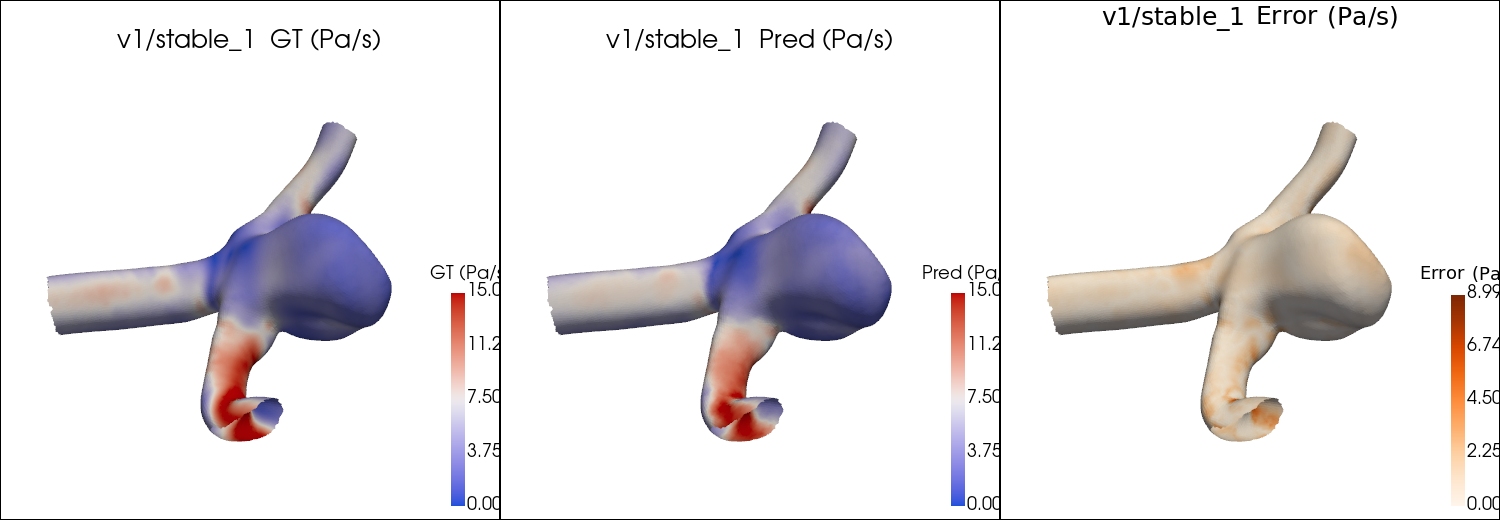

In [7]:
def show_case(run_name, case_idx=0, max_wss=15.0, z_rot=0.0, window_size=(1500, 520)):
    model, args, _ = results[run_name]
    key = test_keys[case_idx]
    batch, gt, pred = predict_case(model, args, key)

    pos = batch.pos.cpu().numpy()
    ei = batch.edge_index.cpu().numpy()
    gt_mag = np.linalg.norm(gt.numpy(), axis=1).clip(0, max_wss)
    pd_mag = np.linalg.norm(pred.numpy(), axis=1).clip(0, max_wss)
    err = np.abs(gt_mag - pd_mag)

    pl = pv.Plotter(shape=(1, 3), window_size=window_size)
    pl.link_views()
    panels = [
        (gt_mag, "GT (Pa/s)",      "coolwarm", [0.0, max_wss]),
        (pd_mag, "Pred (Pa/s)",    "coolwarm", [0.0, max_wss]),
        (err,    "|Error| (Pa/s)", "Oranges",  [0.0, float(err.max())]),
    ]
    for col, (vals, title, cmap, clim) in enumerate(panels):
        pl.subplot(0, col)
        mesh = _make_surface_mesh(pos, ei)
        mesh.rotate_z(z_rot, inplace=True)        # view angle around world z (deg)
        mesh.point_data["wss"] = vals
        pl.add_mesh(mesh, scalars="wss", cmap=cmap, clim=clim, show_scalar_bar=True,
                    scalar_bar_args={"title": title, "vertical": True})
        pl.add_title(f"{key[0]}/{key[1]}  {title}", font_size=10)
    pl.camera_position = "iso"
    pl.show()


show_case(list(RUNS)[0], case_idx=0, max_wss=15.0, z_rot=0.0)

In [8]:
def save_case_images(run_name, idx_start, idx_end, max_wss=15.0, z_rot=0.0,
                     out_dir=None, window_size=(1500, 520)):
    """Render test cases idx_start..idx_end (inclusive) to PNG, two opposite
    views per case (z_rot and z_rot + 180 degrees).

    Images land in <CKPT_ROOT>/<run_name>/visualization/ unless out_dir is given."""
    if out_dir is None:
        out_dir = os.path.join(CKPT_ROOT, run_name, "visualization")
    os.makedirs(out_dir, exist_ok=True)
    model, args, _ = results[run_name]
    for case_idx in range(idx_start, idx_end + 1):
        key = test_keys[case_idx]
        batch, gt, pred = predict_case(model, args, key)
        pos = batch.pos.cpu().numpy()
        ei = batch.edge_index.cpu().numpy()
        gt_mag = np.linalg.norm(gt.numpy(), axis=1).clip(0, max_wss)
        pd_mag = np.linalg.norm(pred.numpy(), axis=1).clip(0, max_wss)
        err = np.abs(gt_mag - pd_mag)
        panels = [
            (gt_mag, "GT (Pa/s)",      "coolwarm", [0.0, max_wss]),
            (pd_mag, "Pred (Pa/s)",    "coolwarm", [0.0, max_wss]),
            (err,    "|Error| (Pa/s)", "Oranges",  [0.0, float(err.max())]),
        ]
        for view, angle in enumerate((z_rot, z_rot + 180.0)):
            pl = pv.Plotter(shape=(1, 3), window_size=window_size, off_screen=True)
            pl.link_views()
            for col, (vals, title, cmap, clim) in enumerate(panels):
                pl.subplot(0, col)
                mesh = _make_surface_mesh(pos, ei)
                mesh.rotate_z(angle, inplace=True)
                mesh.point_data["wss"] = vals
                pl.add_mesh(mesh, scalars="wss", cmap=cmap, clim=clim, show_scalar_bar=True,
                            scalar_bar_args={"title": title, "vertical": True})
                pl.add_title(f"{key[0]}/{key[1]}  {title}", font_size=10)
            pl.camera_position = "iso"
            path = os.path.join(out_dir, f"{key[0]}_{key[1]}_view{view}.png")
            pl.screenshot(path)
            pl.close()
            print("saved", path)




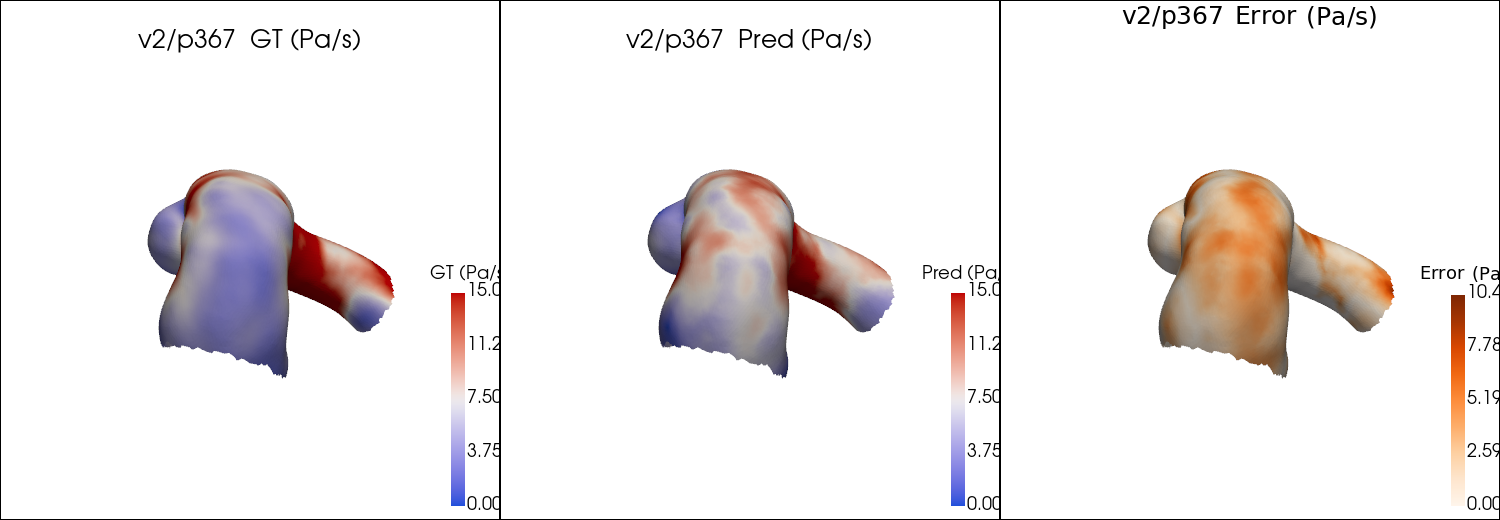

In [9]:
# compare the same case across all registered runs, same viewing angle
CASE_IDX, Z_ROT = 212, 80.0
for name in RUNS:
    show_case(name, case_idx=CASE_IDX, max_wss=15.0, z_rot=Z_ROT)

In [ ]:
# save images 
# save_case_images(list(RUNS)[0], idx_start=0, idx_end=9, max_wss=15.0, z_rot=0.0)
save_case_images(list(RUNS)[0], idx_start=230, idx_end=240, max_wss=15.0, z_rot=0.0)

IndexError: list index out of range

: 